In [1]:
import os, sys, subprocess, warnings
# --- make `src/` importable (local, Colab, Kaggle): use the repo copy if present, else write it ---
DM_UTILS = r'''"""Shared data + preprocessing utilities for Diabetes Risk Miner (DS311).

Imported by the M3 notebook and by the Streamlit app, so that saved
scikit-learn pipelines (which reference `Winsorizer`) can be un-pickled anywhere.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

AGE_LABELS = {
    1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49",
    7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+",
}


def load_clean():
    """Fetch UCI id=891, drop exact duplicates -> (X, y). Same cleaning as M2."""
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    X = ds.data.features.copy()
    y = ds.data.targets.iloc[:, 0].astype(int).copy()
    df = X.assign(target=y.values).drop_duplicates().reset_index(drop=True)
    return df.drop(columns="target"), df["target"].astype(int)


def add_features(d: pd.DataFrame) -> pd.DataFrame:
    """Row-wise engineered features (no cross-row info -> no leakage). Same as M2."""
    d = d.copy()
    d["comorbidity_count"] = d["HighBP"] + d["HighChol"] + d["Stroke"] + d["HeartDiseaseorAttack"]
    d["lifestyle_risk"] = (d["Smoker"] + d["HvyAlcoholConsump"]
                           + (1 - d["PhysActivity"]) + (1 - d["Fruits"]) + (1 - d["Veggies"]))
    d["poor_health_days"] = d["MentHlth"] + d["PhysHlth"]
    d["obese"] = (d["BMI"] >= 30).astype(int)
    return d


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip to train-set quantiles to tame BMI / day-count outliers."""
    def __init__(self, lower=0.005, upper=0.995):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        A = np.asarray(X, float)
        self.lo_ = np.quantile(A, self.lower, axis=0)
        self.hi_ = np.quantile(A, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


def build_preprocess(X_train: pd.DataFrame):
    """Winsorise+scale numeric/ordinal columns, pass binary columns through."""
    bin_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
    num_cols = [c for c in X_train.columns if c not in bin_cols]
    prep = ColumnTransformer([
        ("num", Pipeline([("win", Winsorizer()), ("scale", StandardScaler())]), num_cols),
        ("bin", "passthrough", bin_cols),
    ])
    return prep, num_cols, bin_cols


def best_threshold(y_true, proba, grid=None):
    """Probability threshold that maximises Macro-F1 (choose on validation data only)."""
    from sklearn.metrics import f1_score
    grid = np.linspace(0.1, 0.9, 81) if grid is None else grid
    scores = [f1_score(y_true, proba >= t, average="macro") for t in grid]
    return float(grid[int(np.argmax(scores))])
'''
if not os.path.exists("src/dm_utils.py"):
    if os.path.exists("../src/dm_utils.py"):
        os.chdir("..")
    else:
        os.makedirs("src", exist_ok=True)
        open("src/__init__.py", "w").close()
        open("src/dm_utils.py", "w").write(DM_UTILS)
        print("Created src/dm_utils.py (commit this file to your repo too).")
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo", "xgboost"], check=False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import LocalOutlierFactor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score, recall_score,
                             precision_score, silhouette_score, adjusted_rand_score, confusion_matrix)
from xgboost import XGBClassifier

from src.dm_utils import SEED, AGE_LABELS, load_clean, add_features, build_preprocess, best_threshold

warnings.filterwarnings("ignore")
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)
os.makedirs("figures", exist_ok=True)
CV_SAMPLE = 60_000   # rows used for 5-fold CV model selection (final models are refit on the FULL train set)

Created src/dm_utils.py (commit this file to your repo too).


In [2]:
X, y = load_clean()
X_fe = add_features(X)
X_train, X_test, y_train, y_test = train_test_split(X_fe, y, test_size=0.2, stratify=y, random_state=SEED)
preprocess, num_cols, bin_cols = build_preprocess(X_train)
preprocess.fit(X_train)     # fit on TRAIN only (pipelines below re-fit it per CV fold)
print(f"Rows after de-dup: {len(X):,} | positive rate {y.mean():.3f}")
print(f"Train {X_train.shape} | Test {X_test.shape}")

Rows after de-dup: 229,474 | positive rate 0.153
Train (183579, 25) | Test (45895, 25)


In [3]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=neg / pos, eval_metric="logloss",
                             tree_method="hist", n_jobs=-1, random_state=SEED),
}
pipes = {n: Pipeline([("prep", preprocess), ("clf", m)]) for n, m in models.items()}

# 5-fold stratified CV on a stratified subsample (speed); preprocessing re-fit inside every fold
cv_idx = X_train.sample(min(CV_SAMPLE, len(X_train)), random_state=SEED).index
Xcv, ycv = X_train.loc[cv_idx], y_train.loc[cv_idx]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

rows = []
for name, pipe in pipes.items():
    cv = cross_validate(pipe, Xcv, ycv, cv=skf, n_jobs=1,
                        scoring={"f1m": "f1_macro", "auc": "roc_auc", "ap": "average_precision"})
    pipe.fit(X_train, y_train)                      # final fit on the full training set
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    rows.append({
        "Model": name,
        "CV Macro-F1": cv["test_f1m"].mean(), "CV ROC-AUC": cv["test_auc"].mean(), "CV PR-AUC": cv["test_ap"].mean(),
        "Test Macro-F1": f1_score(y_test, pred, average="macro"),
        "Test ROC-AUC": roc_auc_score(y_test, proba), "Test PR-AUC": average_precision_score(y_test, proba),
        "Test Recall": recall_score(y_test, pred), "Test Precision": precision_score(y_test, pred, zero_division=0),
    })
q1 = pd.DataFrame(rows).set_index("Model").round(4)
q1.to_csv("outputs/q1_model_results.csv")
q1

,CV Macro-F1,CV ROC-AUC,CV PR-AUC,Test Macro-F1,Test ROC-AUC,Test PR-AUC,Test Recall,Test Precision
Model,,,,,,,,
Majority-class baseline,0.4582,0.5000,0.1543,0.4586,0.5000,0.1529,0.0000,0.0000
Logistic Regression,0.6331,0.8086,0.4182,0.6291,0.8118,0.4250,0.7604,0.3195
Random Forest,0.6406,0.8089,0.4231,0.6367,0.8165,0.4413,0.7562,0.3276
XGBoost,0.6317,0.8071,0.4163,0.6292,0.8187,0.4463,0.7874,0.3198


In [4]:
best_name = q1.drop(index="Majority-class baseline")["CV ROC-AUC"].idxmax()
print("Best model by CV ROC-AUC:", best_name)

import sklearn.base as skb
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
tmp = skb.clone(pipes[best_name]).fit(X_fit, y_fit)
thr = best_threshold(y_val, tmp.predict_proba(X_val)[:, 1])

final = pipes[best_name]                       # already fit on full train
proba_te = final.predict_proba(X_test)[:, 1]
pred_te = (proba_te >= thr).astype(int)
tuned = {"threshold": thr,
         "Macro-F1": f1_score(y_test, pred_te, average="macro"),
         "Recall": recall_score(y_test, pred_te), "Precision": precision_score(y_test, pred_te),
         "ROC-AUC": roc_auc_score(y_test, proba_te), "PR-AUC": average_precision_score(y_test, proba_te)}
print({k: round(v, 4) for k, v in tuned.items()})
print("Confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_test, pred_te))
pd.Series(tuned, name=best_name).round(4).to_csv("outputs/q1_best_model_tuned.csv")

Best model by CV ROC-AUC: Random Forest
{'threshold': 0.65, 'Macro-F1': 0.6776, 'Recall': 0.5424, 'Precision': 0.4134, 'ROC-AUC': np.float64(0.8165), 'PR-AUC': np.float64(0.4413)}
Confusion matrix [[TN FP],[FN TP]]:
 [[33475  5401]
 [ 3212  3807]]


GenHlth              0.0459
Age                  0.0261
BMI                  0.0191
comorbidity_count    0.0151
HighBP               0.0042
HvyAlcoholConsump    0.0037
obese                0.0028
DiffWalk             0.0022
CholCheck            0.0019
Sex                  0.0018
dtype: float64


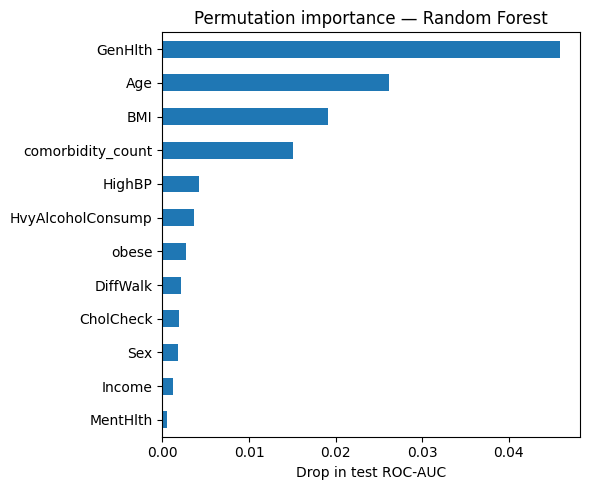

In [5]:
samp = X_test.sample(min(10_000, len(X_test)), random_state=SEED)
pi = permutation_importance(final, samp, y_test.loc[samp.index], scoring="roc_auc",
                            n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.round(4).to_csv("outputs/q1_feature_importance.csv", header=["perm_importance_auc_drop"])
print(imp.head(10).round(4))
imp.head(12)[::-1].plot.barh(figsize=(6, 5), title=f"Permutation importance — {best_name}")
plt.xlabel("Drop in test ROC-AUC"); plt.tight_layout(); plt.savefig("figures/q1_permutation_importance.png", dpi=150); plt.show()

PCA keeps 11/25 components (≥90 % variance)
    inertia_PCA  silhouette_PCA  silhouette_noPCA
k                                                
2  1.647806e+06          0.3203            0.3018
3  1.445758e+06          0.1559            0.1405
4  1.350001e+06          0.1220            0.1088
5  1.259654e+06          0.1309            0.1156
6  1.194925e+06          0.1265            0.1104
7  1.141491e+06          0.1209            0.1043
8  1.093656e+06          0.1258            0.1086


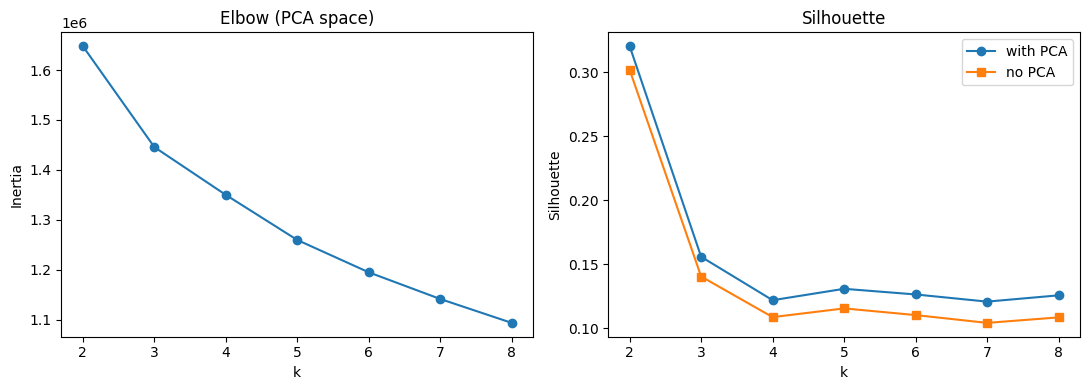

Chosen k = 3


In [6]:
Z_train = preprocess.transform(X_train)                       # preprocess fit on the train split only
feat_names = [n.split("__", 1)[1] for n in preprocess.get_feature_names_out()]
pca_full = PCA(random_state=SEED).fit(Z_train)
n_comp = int(np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.90) + 1)
pca = PCA(n_components=n_comp, random_state=SEED).fit(Z_train)
P_train = pca.transform(Z_train)
print(f"PCA keeps {n_comp}/{Z_train.shape[1]} components (≥90 % variance)")

rs = np.random.RandomState(SEED)
sil_idx = rs.choice(len(Z_train), min(10_000, len(Z_train)), replace=False)
res = []
for k in range(2, 9):
    km_p = KMeans(k, n_init=5, random_state=SEED).fit(P_train)
    km_r = KMeans(k, n_init=5, random_state=SEED).fit(Z_train)
    res.append({"k": k, "inertia_PCA": km_p.inertia_,
                "silhouette_PCA": silhouette_score(P_train[sil_idx], km_p.labels_[sil_idx]),
                "silhouette_noPCA": silhouette_score(Z_train[sil_idx], km_r.labels_[sil_idx])})
sel = pd.DataFrame(res).set_index("k").round(4)
sel.to_csv("outputs/q2_k_selection.csv")
print(sel)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sel.index, sel["inertia_PCA"], marker="o"); ax[0].set(xlabel="k", ylabel="Inertia", title="Elbow (PCA space)")
ax[1].plot(sel.index, sel["silhouette_PCA"], marker="o", label="with PCA")
ax[1].plot(sel.index, sel["silhouette_noPCA"], marker="s", label="no PCA")
ax[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/q2_elbow_silhouette.png", dpi=150); plt.show()

K = int(sel.loc[3:8, "silhouette_PCA"].idxmax())
print("Chosen k =", K)

In [7]:
km = KMeans(K, n_init=10, random_state=SEED).fit(P_train)
labels = km.labels_
# stability: re-run with another seed on the same data, compare partitions
ari = adjusted_rand_score(labels, KMeans(K, n_init=10, random_state=SEED + 1).fit(P_train).labels_)
print(f"Seed-stability (Adjusted Rand Index between two runs): {ari:.3f}")

prof_df = X_train.assign(cluster=labels, diabetes=y_train.values)
prof_df["female"] = (prof_df["Sex"] == 0).astype(int)
prof_df["age_years_mid"] = prof_df["Age"].map(lambda a: {1:21,2:27,3:32,4:37,5:42,6:47,7:52,8:57,9:62,10:67,11:72,12:77,13:82}[a])
cols = ["age_years_mid", "female", "BMI", "GenHlth", "Income", "Education", "comorbidity_count",
        "lifestyle_risk", "poor_health_days", "HighBP", "HighChol", "HeartDiseaseorAttack", "DiffWalk", "PhysActivity"]
profile = prof_df.groupby("cluster")[cols].mean()
profile.insert(0, "size_%", prof_df["cluster"].value_counts(normalize=True).sort_index() * 100)
profile.insert(1, "diabetes_rate_%", prof_df.groupby("cluster")["diabetes"].mean() * 100)

# what makes each cluster distinctive: largest standardised deviation from the population mean
z = (profile[cols] - prof_df[cols].mean()) / prof_df[cols].std()
profile["distinguishing_traits"] = [", ".join(f"{c} {'↑' if z.loc[i, c] > 0 else '↓'}" for c in z.loc[i].abs().sort_values(ascending=False).index[:3])
                                    for i in z.index]
profile = profile.sort_values("diabetes_rate_%").round(2)
profile.to_csv("outputs/q2_cluster_profiles.csv")
profile

Seed-stability (Adjusted Rand Index between two runs): 0.995


,size_%,diabetes_rate_%,age_years_mid,female,BMI,GenHlth,Income,Education,comorbidity_count,lifestyle_risk,poor_health_days,HighBP,HighChol,HeartDiseaseorAttack,DiffWalk,PhysActivity,distinguishing_traits
cluster,,,,,,,,,,,,,,,,,
1,47.05,4.52,50.05,0.57,27.00,2.02,6.75,5.35,0.40,1.02,3.14,0.16,0.21,0.01,0.03,0.86,"comorbidity_count ↓, HighBP ↓, GenHlth ↓"
0,37.48,23.75,65.82,0.53,30.01,2.82,5.38,4.67,1.66,1.65,2.99,0.75,0.67,0.17,0.21,0.67,"comorbidity_count ↑, HighBP ↑, age_years_mid ↑"
2,15.47,27.59,59.30,0.62,30.55,3.85,4.51,4.61,1.51,1.85,36.17,0.62,0.57,0.21,0.58,0.52,"poor_health_days ↑, GenHlth ↑, DiffWalk ↑"


Age      18-39  40-59  60-69   70+  Female %  Low income (≤3) %
cluster                                                        
1         27.1   43.7   19.4   9.8      56.6                5.8
0          2.7   24.2   32.4  40.8      53.2               20.9
2          9.1   39.3   28.1  23.5      62.3               37.2


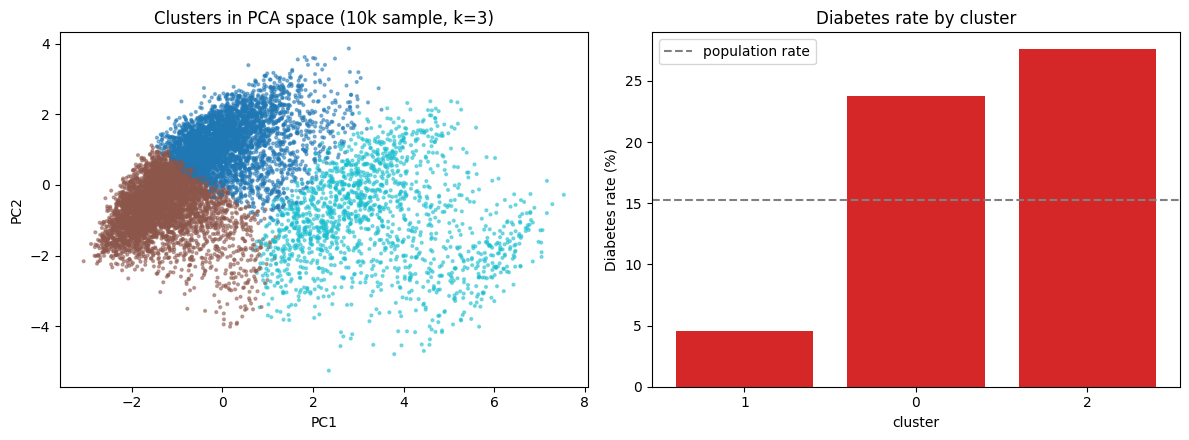

In [8]:
# Demographic differences across clusters (Q2: "how do they differ across demographic groups?")
age_band = pd.cut(prof_df["Age"], [0, 4, 8, 10, 13], labels=["18-39", "40-59", "60-69", "70+"])
demo = pd.crosstab(prof_df["cluster"], age_band, normalize="index").mul(100).round(1)
demo["Female %"] = (prof_df.groupby("cluster")["female"].mean() * 100).round(1)
demo["Low income (≤3) %"] = (prof_df.assign(low=(prof_df["Income"] <= 3)).groupby("cluster")["low"].mean() * 100).round(1)
demo.loc[profile.index].to_csv("outputs/q2_cluster_demographics.csv")
print(demo.loc[profile.index])

order = profile.index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
p2 = PCA(2, random_state=SEED).fit_transform(Z_train[sil_idx])
sc = ax[0].scatter(p2[:, 0], p2[:, 1], c=labels[sil_idx], cmap="tab10", s=4, alpha=0.5)
ax[0].set(xlabel="PC1", ylabel="PC2", title=f"Clusters in PCA space (10k sample, k={K})")
ax[1].bar([str(c) for c in order], profile.loc[order, "diabetes_rate_%"], color="tab:red")
ax[1].axhline(y_train.mean() * 100, ls="--", c="gray", label="population rate")
ax[1].set(xlabel="cluster", ylabel="Diabetes rate (%)", title="Diabetes rate by cluster"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/q2_clusters.png", dpi=150); plt.show()

                               n_flagged  share_%  diabetes_rate_%
Isolation Forest (full train)     1836.0      1.0            33.12
LOF (20k sample)                   200.0      1.0            11.00
Population baseline                  NaN      NaN            15.29

IF ∩ LOF overlap on the 20k sample (Jaccard): 0.01

Mean of key features — normal vs Isolation-Forest outliers:
                BMI  GenHlth  comorbidity_count  poor_health_days   Age  Income
iso_outlier                                                                   
False        28.64     2.58               1.03              7.83  8.08    5.92
True         31.87     4.35               2.47             44.01  8.03    3.09

Share of outliers in each cluster (%):
 cluster
0     7.8
1     0.2
2    92.0
Name: True, dtype: float64

Outlier rate within each cluster (%):
 cluster
0    0.21
1    0.00
2    5.95
Name: iso_outlier, dtype: float64


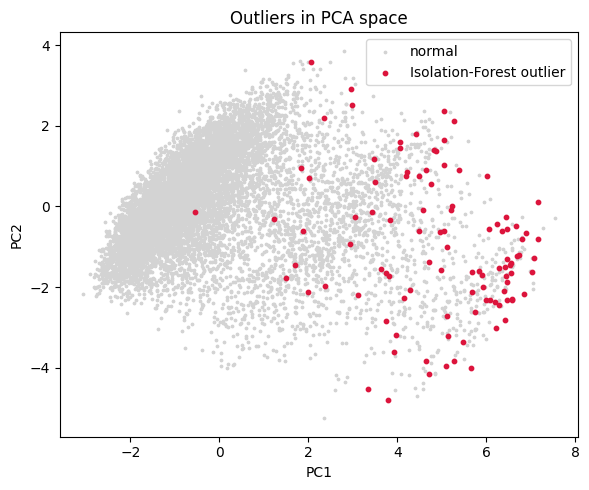

In [9]:
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED, n_jobs=-1).fit(Z_train)
iso_flag = iso.predict(Z_train) == -1

lof_idx = rs.choice(len(Z_train), min(20_000, len(Z_train)), replace=False)
lof = LocalOutlierFactor(n_neighbors=35, contamination=0.01, n_jobs=-1)
lof_flag_s = lof.fit_predict(Z_train[lof_idx]) == -1
iso_flag_s = iso_flag[lof_idx]
overlap = (iso_flag_s & lof_flag_s).sum() / max((iso_flag_s | lof_flag_s).sum(), 1)

out = prof_df.assign(iso_outlier=iso_flag)
summary = pd.DataFrame({
    "n_flagged": [iso_flag.sum(), lof_flag_s.sum()],
    "share_%": [iso_flag.mean() * 100, lof_flag_s.mean() * 100],
    "diabetes_rate_%": [y_train[iso_flag].mean() * 100, y_train.values[lof_idx][lof_flag_s].mean() * 100],
}, index=["Isolation Forest (full train)", "LOF (20k sample)"]).round(2)
summary.loc["Population baseline", "diabetes_rate_%"] = round(y_train.mean() * 100, 2)
summary.to_csv("outputs/outlier_summary.csv")
print(summary)
print(f"\nIF ∩ LOF overlap on the 20k sample (Jaccard): {overlap:.2f}")

dist = out.groupby("iso_outlier")[["BMI", "GenHlth", "comorbidity_count", "poor_health_days", "Age", "Income"]].mean().round(2)
print("\nMean of key features — normal vs Isolation-Forest outliers:\n", dist)
print("\nShare of outliers in each cluster (%):\n", (pd.crosstab(out["cluster"], out["iso_outlier"], normalize="columns")[True] * 100).round(1))
print("\nOutlier rate within each cluster (%):\n", (out.groupby("cluster")["iso_outlier"].mean() * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(p2[:, 0], p2[:, 1], s=3, c="lightgray", label="normal")
f = iso_flag[sil_idx]
ax.scatter(p2[f, 0], p2[f, 1], s=10, c="crimson", label="Isolation-Forest outlier")
ax.set(xlabel="PC1", ylabel="PC2", title="Outliers in PCA space"); ax.legend()
plt.tight_layout(); plt.savefig("figures/outliers_pca.png", dpi=150); plt.show()

In [10]:
d = X_fe.assign(diabetes=y.values)
d["poor_health"] = (d["GenHlth"] >= 4).astype(int)
d["cardio"] = d["HeartDiseaseorAttack"]

drop_always = ["cardio", "poor_health"]
drop_for = {   # target -> columns that leak it (the target itself, columns derived from it, or its symptoms)
    "cardio":      ["HeartDiseaseorAttack", "comorbidity_count", "Stroke", "GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "poor_health_days"],
    "poor_health": ["GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "poor_health_days"],
}

target_src = {"cardio": ["HeartDiseaseorAttack"], "poor_health": ["GenHlth"]}   # the column each target is built from

def q3_models():
    return {
        "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "Gradient Boosting": HistGradientBoostingClassifier(max_depth=5, learning_rate=0.1, max_iter=200,
                                                            class_weight="balanced", random_state=SEED),
    }

def run_target(tname, drop_cols, models=None):
    feats = [c for c in d.columns if c not in drop_always + drop_cols]
    Xa, ya = d[feats], d[tname]
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=SEED)  # stratified split
    out = {}
    for n, m in (models or q3_models()).items():
        pipe = Pipeline([("prep", build_preprocess(Xtr)[0]), ("clf", m)]).fit(Xtr, ytr)
        p = pipe.predict_proba(Xte)[:, 1]
        out[n] = {"Macro-F1": f1_score(yte, pipe.predict(Xte), average="macro"),
                  "PR-AUC": average_precision_score(yte, p), "ROC-AUC": roc_auc_score(yte, p), "base_rate": yte.mean()}
    return pd.DataFrame(out).T, feats

q3_rows = []
for tname in ["cardio", "poor_health"]:
    r, feats = run_target(tname, drop_for[tname])
    r.insert(0, "target", tname)
    q3_rows.append(r)
    print(f"\n=== {tname} | {len(feats)} baseline features | positive rate {r['base_rate'].iloc[0]:.3f}")
    print(r.drop(columns=["target", "base_rate"]).round(4))
q3 = pd.concat(q3_rows).rename_axis("Model").reset_index().round(4)
q3.to_csv("outputs/q3_model_results.csv", index=False)


=== cardio | 18 baseline features | positive rate 0.103
                         Macro-F1  PR-AUC  ROC-AUC
Majority-class baseline    0.4728  0.1033   0.5000
Decision Tree              0.5594  0.2725   0.7935
Random Forest              0.5829  0.2989   0.8064
Gradient Boosting          0.5766  0.3006   0.8094

=== poor_health | 21 baseline features | positive rate 0.190
                         Macro-F1  PR-AUC  ROC-AUC
Majority-class baseline    0.4475  0.1901   0.5000
Decision Tree              0.6541  0.4849   0.7957
Random Forest              0.6787  0.5326   0.8143
Gradient Boosting          0.6784  0.5392   0.8174


In [11]:
leak_rows = []
for tname in ["cardio", "poor_health"]:
    gb = {"Gradient Boosting": q3_models()["Gradient Boosting"]}
    safe, _ = run_target(tname, drop_for[tname], gb)
    leaky, _ = run_target(tname, target_src[tname], gb)   # only the target's own source column is removed
    leak_rows.append({"target": tname,
                      "PR-AUC safe": safe["PR-AUC"].iloc[0], "PR-AUC with suspect cols": leaky["PR-AUC"].iloc[0],
                      "Macro-F1 safe": safe["Macro-F1"].iloc[0], "Macro-F1 with suspect cols": leaky["Macro-F1"].iloc[0],
                      "columns removed": ", ".join(drop_for[tname])})
leak = pd.DataFrame(leak_rows).round(4)
leak.to_csv("outputs/q3_leakage_check.csv", index=False)
leak

,target,PR-AUC safe,PR-AUC with suspect cols,Macro-F1 safe,Macro-F1 with suspect cols,columns removed
0,cardio,0.3006,1.000,0.5766,1.0000,"HeartDiseaseorAttack, comorbidity_count, Strok..."
1,poor_health,0.5392,0.712,0.6784,0.7621,"GenHlth, MentHlth, PhysHlth, DiffWalk, poor_he..."


In [12]:
joblib.dump({"pipeline": final, "threshold": thr, "model_name": best_name,
             "base_rate": float(y_train.mean()), "columns": list(X_train.columns),
             "test_metrics": {k: float(v) for k, v in tuned.items()}}, "outputs/risk_model.joblib", compress=3)

names = {c: f"Cluster {c} — {profile.loc[c, 'distinguishing_traits']}" for c in profile.index}
joblib.dump({"preprocess": preprocess, "pca": pca, "kmeans": km, "k": K, "names": names,
             "diabetes_rate": profile["diabetes_rate_%"].to_dict()}, "outputs/cluster_model.joblib", compress=3)
print("Saved:", sorted(os.listdir("outputs")))

Saved: ['cluster_model.joblib', 'outlier_summary.csv', 'q1_best_model_tuned.csv', 'q1_feature_importance.csv', 'q1_model_results.csv', 'q2_cluster_demographics.csv', 'q2_cluster_profiles.csv', 'q2_k_selection.csv', 'q3_leakage_check.csv', 'q3_model_results.csv', 'risk_model.joblib']
